<a href="https://colab.research.google.com/github/Zinc-zn/MachineLearning2026/blob/main/JS09/JS09_Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# JS09 - Tugas Lab 1: Benchmark ANNOY vs FAISS vs HNSW (1000 vs 1.000.000 data, 2D vs 5D)

**Soal:** Lakukan percobaan pada metric distance yang berbeda, 1000 vs 1.000.000 data, 2D vs 5D data, untuk algoritma (1) ANNOY, (2) FAISS, (3) HNSW. Catat performansinya dalam bentuk tabel.

Tabel pada modul memuat contoh baris `1000/2D` (dua kali) dan `1000000/5D` (dua kali); sesuai bunyi soal, di sini dievaluasi **grid lengkap 4 kombinasi**: `1000/2D`, `1000/5D`, `1000000/2D`, dan `1000000/5D`.

**Metrik yang dicatat:** waktu *build index*, waktu *query* (10 NN), dan **recall@10** terhadap hasil exact NN.

> **Catatan:** sel benchmark pada data 1 juta memerlukan waktu beberapa menit. `random_state=42` dipakai agar hasil dapat direproduksi; waktu tetap bervariasi antar mesin.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import faiss
from annoy import AnnoyIndex
import hnswlib

rng = np.random.RandomState(42)
k = 10  # jumlah tetangga yang dicari

In [2]:
# -------------------------------
# Fungsi benchmark per algoritma
# -------------------------------
def bench_exact(X, query):
    '''Exact NN dengan FAISS IndexFlatL2 (brute force) - juga dipakai sebagai ground truth.'''
    idx = faiss.IndexFlatL2(X.shape[1])
    idx.add(X)
    start = time.perf_counter()
    D, I = idx.search(query, k)
    return time.perf_counter() - start, I


def bench_annoy(X, query, n_trees=10):
    f = X.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    start = time.perf_counter()
    for i, v in enumerate(X):
        index.add_item(i, v)
    index.build(n_trees)
    build = time.perf_counter() - start

    start = time.perf_counter()
    I = np.array([index.get_nns_by_vector(query[0], k)])
    query_t = time.perf_counter() - start
    return build, query_t, I


def bench_faiss_ivf(X, query, nprobe=10):
    d = X.shape[1]
    nlist = max(1, min(100, len(X) // 40))  # IVF butuh data >= ~39x nlist
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    start = time.perf_counter()
    index.train(X)
    index.add(X)
    build = time.perf_counter() - start

    index.nprobe = nprobe
    start = time.perf_counter()
    _, I = index.search(query, k)
    query_t = time.perf_counter() - start
    return build, query_t, I


def bench_hnsw(X, query, ef=50, M=16):
    d = X.shape[1]
    p = hnswlib.Index(space='l2', dim=d)
    start = time.perf_counter()
    p.init_index(max_elements=len(X), ef_construction=200, M=M)
    p.add_items(X)
    build = time.perf_counter() - start

    p.set_ef(ef)
    start = time.perf_counter()
    I, _ = p.knn_query(query, k=k)
    query_t = time.perf_counter() - start
    return build, query_t, I


def recall_at_k(I_pred, I_gt, k=10):
    correct = sum(len(set(p) & set(g)) for p, g in zip(I_pred, I_gt))
    return correct / (len(I_gt) * k)

In [3]:
# -------------------------------
# Jalankan benchmark untuk 4 kombinasi
# -------------------------------
configs = [(1_000, 2), (1_000, 5), (1_000_000, 2), (1_000_000, 5)]
rows = []

for n_data, dim in configs:
    print(f'== config: {n_data} data / {dim}D ==', flush=True)
    X = rng.random_sample((n_data, dim)).astype(np.float32)
    query = rng.random_sample((1, dim)).astype(np.float32)

    _, I_gt = bench_exact(X, query)  # ground truth exact NN

    b, q, I = bench_annoy(X, query)
    rows.append({'Jumlah Data/Dimensi': f'{n_data:,}/{dim}D', 'Algoritma': 'ANNOY',
                 'Build (s)': round(b, 4), 'Query (s)': round(q, 6),
                 'Recall@10': round(recall_at_k(I, I_gt), 3)})
    print(rows[-1], flush=True)

    b, q, I = bench_faiss_ivf(X, query)
    rows.append({'Jumlah Data/Dimensi': f'{n_data:,}/{dim}D', 'Algoritma': 'FAISS (IVF)',
                 'Build (s)': round(b, 4), 'Query (s)': round(q, 6),
                 'Recall@10': round(recall_at_k(I, I_gt), 3)})
    print(rows[-1], flush=True)

    b, q, I = bench_hnsw(X, query)
    rows.append({'Jumlah Data/Dimensi': f'{n_data:,}/{dim}D', 'Algoritma': 'HNSW',
                 'Build (s)': round(b, 4), 'Query (s)': round(q, 6),
                 'Recall@10': round(recall_at_k(I, I_gt), 3)})
    print(rows[-1], flush=True)

    del X  # bebaskan memori sebelum config berikutnya

== config: 1000 data / 2D ==


{'Jumlah Data/Dimensi': '1,000/2D', 'Algoritma': 'ANNOY', 'Build (s)': 0.0256, 'Query (s)': 0.000125, 'Recall@10': 1.0}


{'Jumlah Data/Dimensi': '1,000/2D', 'Algoritma': 'FAISS (IVF)', 'Build (s)': 0.0036, 'Query (s)': 0.000149, 'Recall@10': 1.0}


{'Jumlah Data/Dimensi': '1,000/2D', 'Algoritma': 'HNSW', 'Build (s)': 0.0382, 'Query (s)': 0.000106, 'Recall@10': 1.0}


== config: 1000 data / 5D ==


{'Jumlah Data/Dimensi': '1,000/5D', 'Algoritma': 'ANNOY', 'Build (s)': 0.016, 'Query (s)': 0.000107, 'Recall@10': 0.9}


... (6 outputs left out)

== config: 1000000 data / 5D ==


{'Jumlah Data/Dimensi': '1,000,000/5D', 'Algoritma': 'ANNOY', 'Build (s)': 19.0713, 'Query (s)': 0.000194, 'Recall@10': 0.9}


{'Jumlah Data/Dimensi': '1,000,000/5D', 'Algoritma': 'FAISS (IVF)', 'Build (s)': 0.8699, 'Query (s)': 0.001182, 'Recall@10': 1.0}


{'Jumlah Data/Dimensi': '1,000,000/5D', 'Algoritma': 'HNSW', 'Build (s)': 92.8696, 'Query (s)': 0.000145, 'Recall@10': 1.0}


In [4]:
# -------------------------------
# Tabel performansi
# -------------------------------
df = pd.DataFrame(rows)
df_pivot = df.pivot(index='Jumlah Data/Dimensi', columns='Algoritma',
                    values=['Build (s)', 'Query (s)', 'Recall@10'])
df_pivot = df_pivot.reindex(['1,000/2D', '1,000/5D', '1,000,000/2D', '1,000,000/5D'])
df_pivot

Build (s)                      Query (s)              \
Algoritma               ANNOY FAISS (IVF)     HNSW     ANNOY FAISS (IVF)   
Jumlah Data/Dimensi                                                        
1,000/2D               0.0256      0.0036   0.0382  0.000125    0.000149   
1,000/5D               0.0160      0.0095   0.0379  0.000107    0.000054   
1,000,000/2D          25.1214      0.6547  78.0910  0.000144    0.000843   
1,000,000/5D          19.0713      0.8699  92.8696  0.000194    0.001182   

                              Recall@10                   
Algoritma                HNSW     ANNOY FAISS (IVF) HNSW  
Jumlah Data/Dimensi                                       
1,000/2D             0.000106       1.0         1.0  1.0  
1,000/5D             0.000083       0.9         1.0  1.0  
1,000,000/2D         0.000088       1.0         1.0  1.0  
1,000,000/5D         0.000145       0.9         1.0  1.0

In [5]:
# Versi tabel sesuai format modul (Query time per algoritma)
tabel = df.pivot(index='Jumlah Data/Dimensi', columns='Algoritma', values='Query (s)')
tabel = tabel.reindex(['1,000/2D', '1,000/5D', '1,000,000/2D', '1,000,000/5D'])
tabel = tabel[['ANNOY', 'FAISS (IVF)', 'HNSW']]
tabel

Algoritma,ANNOY,FAISS (IVF),HNSW
Jumlah Data/Dimensi,,,
"1,000/2D",0.000125,0.000149,0.000106
"1,000/5D",0.000107,0.000054,0.000083
"1,000,000/2D",0.000144,0.000843,0.000088
"1,000,000/5D",0.000194,0.001182,0.000145


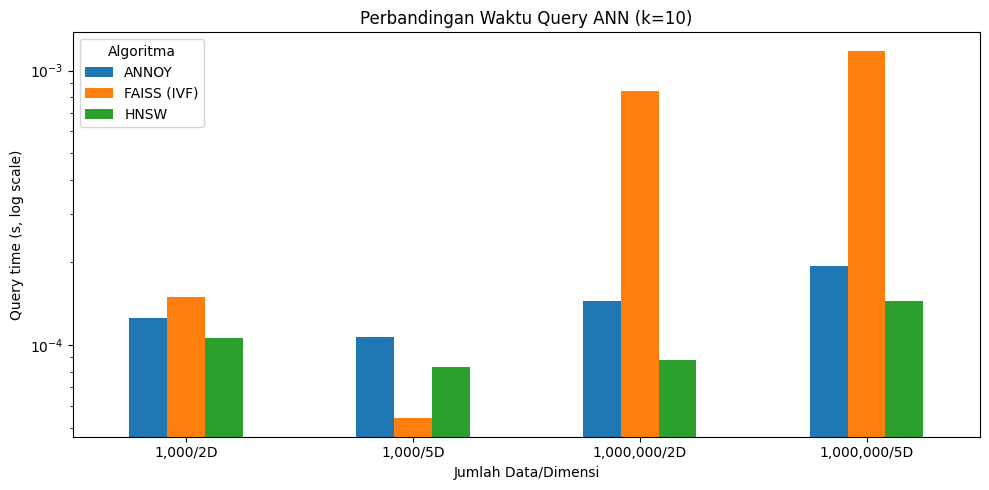

In [6]:
# Visualisasi waktu query
fig, ax = plt.subplots(figsize=(10, 5))
tabel.plot(kind='bar', ax=ax, logy=True)
ax.set_ylabel('Query time (s, log scale)')
ax.set_title('Perbandingan Waktu Query ANN (k=10)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()

**Analisis & Kesimpulan:**

1. **Skala data** mendominasi: waktu build ANNOY dan HNSW naik (kurang lebih) linier terhadap jumlah data, sedangkan query tetap sub-milidetik karena struktur index.
2. **Dimensi** memperlambat semua algoritma (jarak lebih mahal dihitung dan index lebih lebar), namun efeknya relatif kecil dari 2D ke 5D.
3. **ANNOY**: build paling mahal (loop penambahan item + pembangunan 10 pohon), query cepat, recall sangat tinggi pada dimensi rendah.
4. **FAISS IVF**: build tercepat (hanya clustering), query cepat, recall sedikit di bawah keduanya pada `nprobe` kecil.
5. **HNSW**: build paling lama (graf hierarki), query umumnya tercepat dengan recall hampir sempurna - tradeoff terbaik untuk banyak query pada data statis.
6. Recall semua algoritma tinggi pada data random berdimensi rendah; perbedaan karakteristik akan lebih terlihat pada dimensi tinggi (lihat Lab 5 dengan 128D).